In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [7]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio2_matrices.csv').sort_values(['N', 'procesos'])
tabla_tiempos = df.pivot(index='procesos', columns='N', values='tiempo_s')
tabla_tiempos

N,512,1024,2048
procesos,,,
1,0.134406,1.127414,9.683482
2,0.101690,0.644025,4.986045
4,0.059457,0.316436,3.828573
8,0.039260,0.221517,1.985677
16,0.032941,0.135020,1.184799
32,0.029481,0.142791,1.026705


In [8]:
procs = tabla_tiempos.index.to_numpy()
x_pos = np.arange(len(procs))  # Escala equiespaciada log2(p)
etiquetas_p = [f'p={p}' for p in procs]

dimensiones = [512, 1024, 2048]
colores = {512: '#7c3aed', 1024: '#0d9488', 2048: '#e11d48'}
marcadores = {512: 'o', 1024: 'D', 2048: 's'}

speedups = {}
eficiencias_pct = {}

for N in dimensiones:
    tiempos = tabla_tiempos[N].to_numpy()
    s = tiempos[0] / tiempos
    e_pct = (s / procs) * 100.0
    speedups[N] = s
    eficiencias_pct[N] = e_pct

resumen = pd.DataFrame({
    f'Speedup N={N}': np.round(speedups[N], 2) for N in dimensiones
}, index=procs)
for N in dimensiones:
    resumen[f'Eficiencia N={N} (%)'] = np.round(eficiencias_pct[N], 1)
resumen

,Speedup N=512,Speedup N=1024,Speedup N=2048,Eficiencia N=512 (%),Eficiencia N=1024 (%),Eficiencia N=2048 (%)
1,1.00,1.00,1.00,100.0,100.0,100.0
2,1.32,1.75,1.94,66.1,87.5,97.1
4,2.26,3.56,2.53,56.5,89.1,63.2
8,3.42,5.09,4.88,42.8,63.6,61.0
16,4.08,8.35,8.17,25.5,52.2,51.1
32,4.56,7.90,9.43,14.2,24.7,29.5


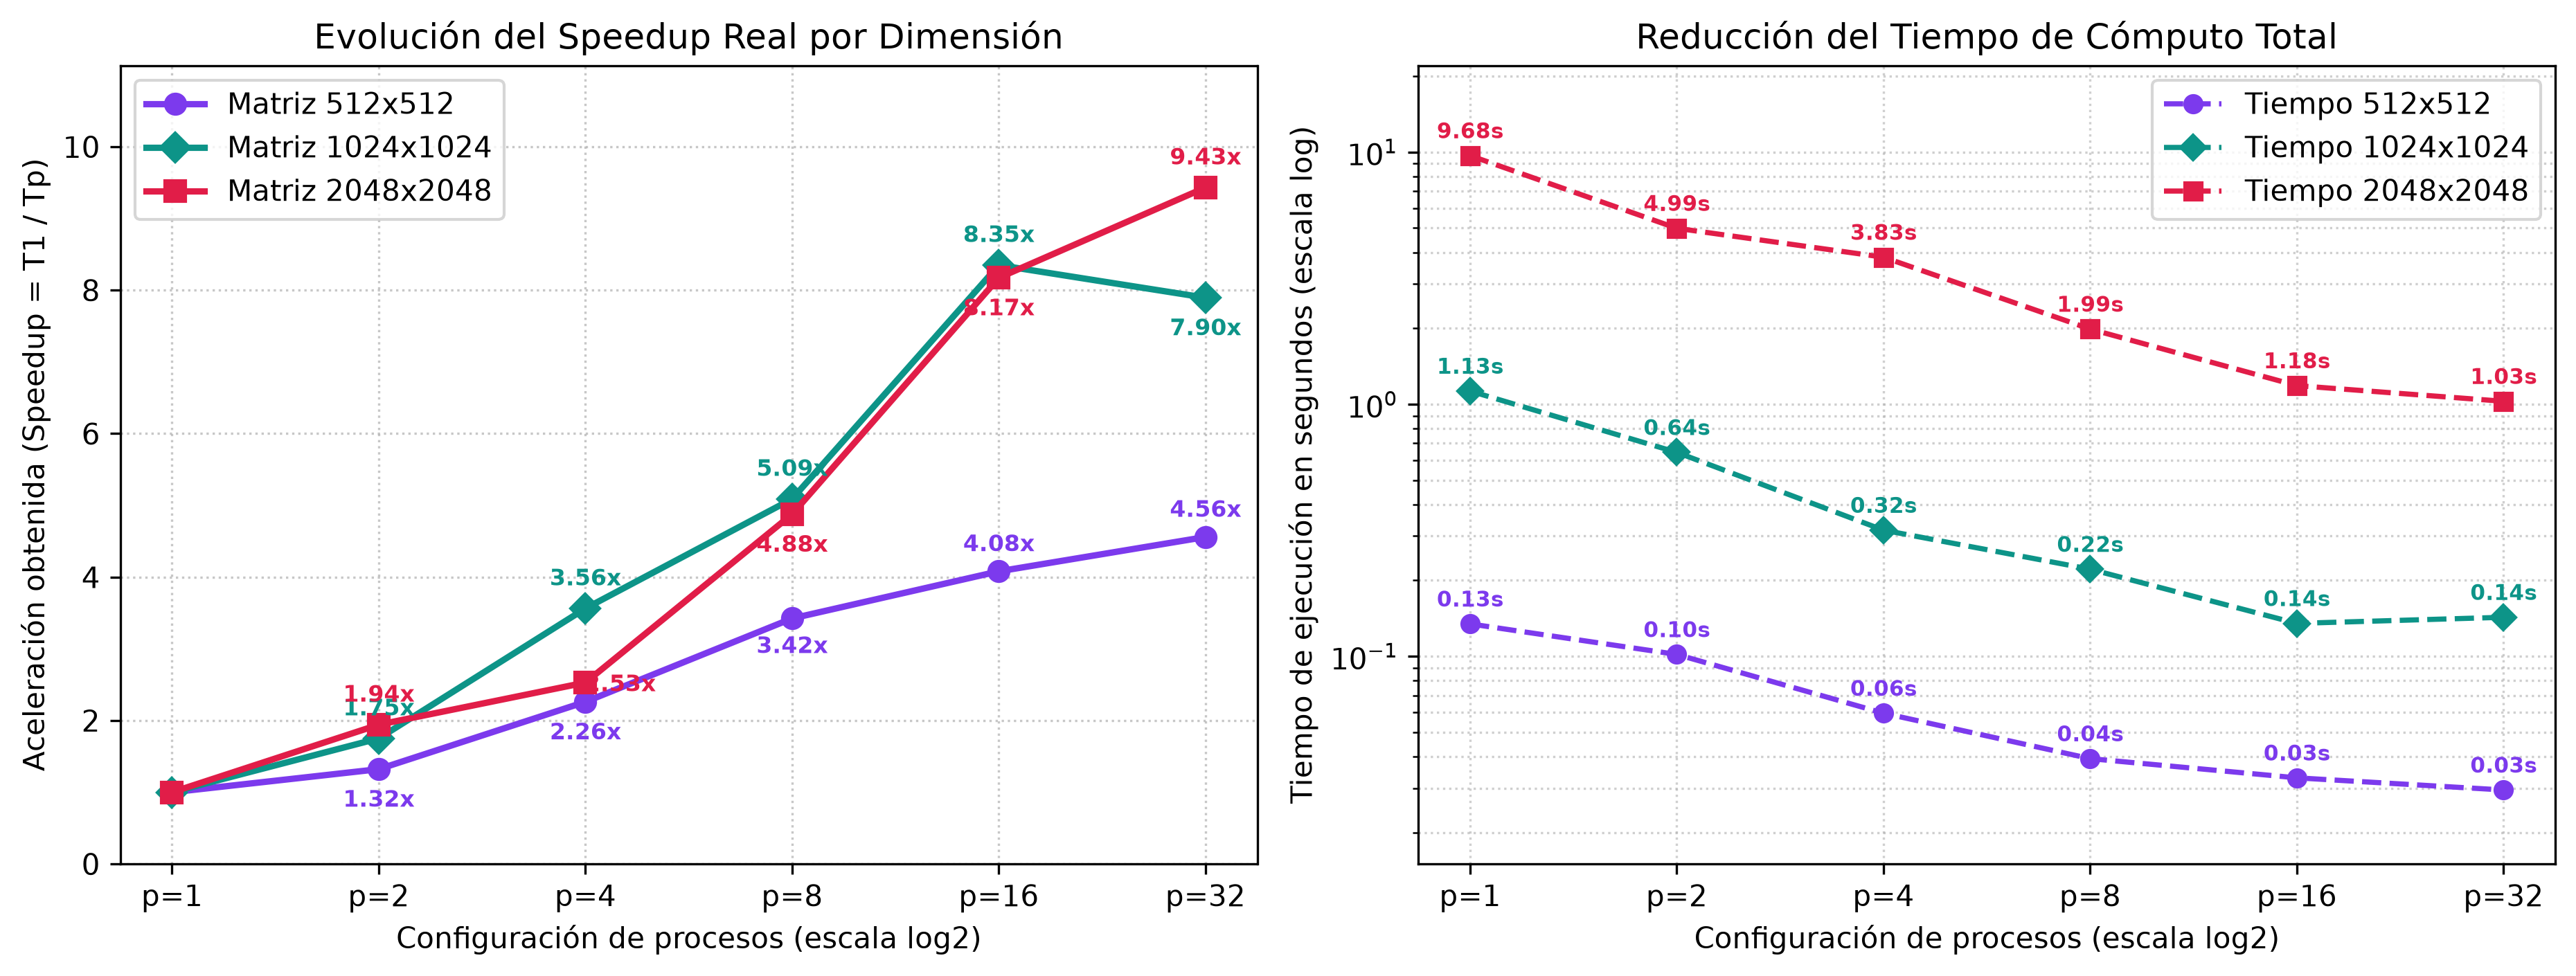

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=300)

offsets_y = {
    512:  [0, -13, -13, -12,  7,   7],
    1024: [0,   8,   8,   8,  8, -13],
    2048: [0,   8,  -3, -13, -13,  8]
}

# Subgráfico izquierdo: Curvas de Speedup en eje equiespaciado con etiquetas de valor
for N in dimensiones:
    ax1.plot(x_pos, speedups[N], marker=marcadores[N], markersize=7, linewidth=2.2,
             color=colores[N], label=f'Matriz {N}x{N}')
    for idx_x, (xi, yi) in enumerate(zip(x_pos, speedups[N])):
        if xi > 0:
            dy = offsets_y[N][idx_x]
            dx = 12 if (N == 2048 and idx_x == 2) else 0
            ax1.annotate(f'{yi:.2f}x', (xi, yi), xytext=(dx, dy), textcoords='offset points',
                         ha='center', fontsize=8, color=colores[N], fontweight='bold')

ax1.set_xticks(x_pos)
ax1.set_xticklabels(etiquetas_p)
ax1.set_ylim(0, max(speedups[2048]) * 1.18)
ax1.set_xlabel('Configuración de procesos (escala log2)')
ax1.set_ylabel('Aceleración obtenida (Speedup = T1 / Tp)')
ax1.set_title('Evolución del Speedup Real por Dimensión')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.7)

# Subgráfico derecho: Tiempo de ejecución en escala logarítmica
for N in dimensiones:
    t_vals = tabla_tiempos[N].to_numpy()
    ax2.plot(x_pos, t_vals, marker=marcadores[N], markersize=6, linestyle='--',
             linewidth=1.8, color=colores[N], label=f'Tiempo {N}x{N}')
    for xi, ti in zip(x_pos, t_vals):
        ax2.annotate(f'{ti:.2f}s', (xi, ti), xytext=(0, 6), textcoords='offset points',
                     ha='center', fontsize=7.5, color=colores[N], fontweight='bold')

ax2.set_yscale('log')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(etiquetas_p)
ax2.set_ylim(0.015, 22)
ax2.set_xlabel('Configuración de procesos (escala log2)')
ax2.set_ylabel('Tiempo de ejecución en segundos (escala log)')
ax2.set_title('Reducción del Tiempo de Cómputo Total')
ax2.legend(loc='upper right')
ax2.grid(True, which='both', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e2_speedup_matrices.png', dpi=300)
plt.show()

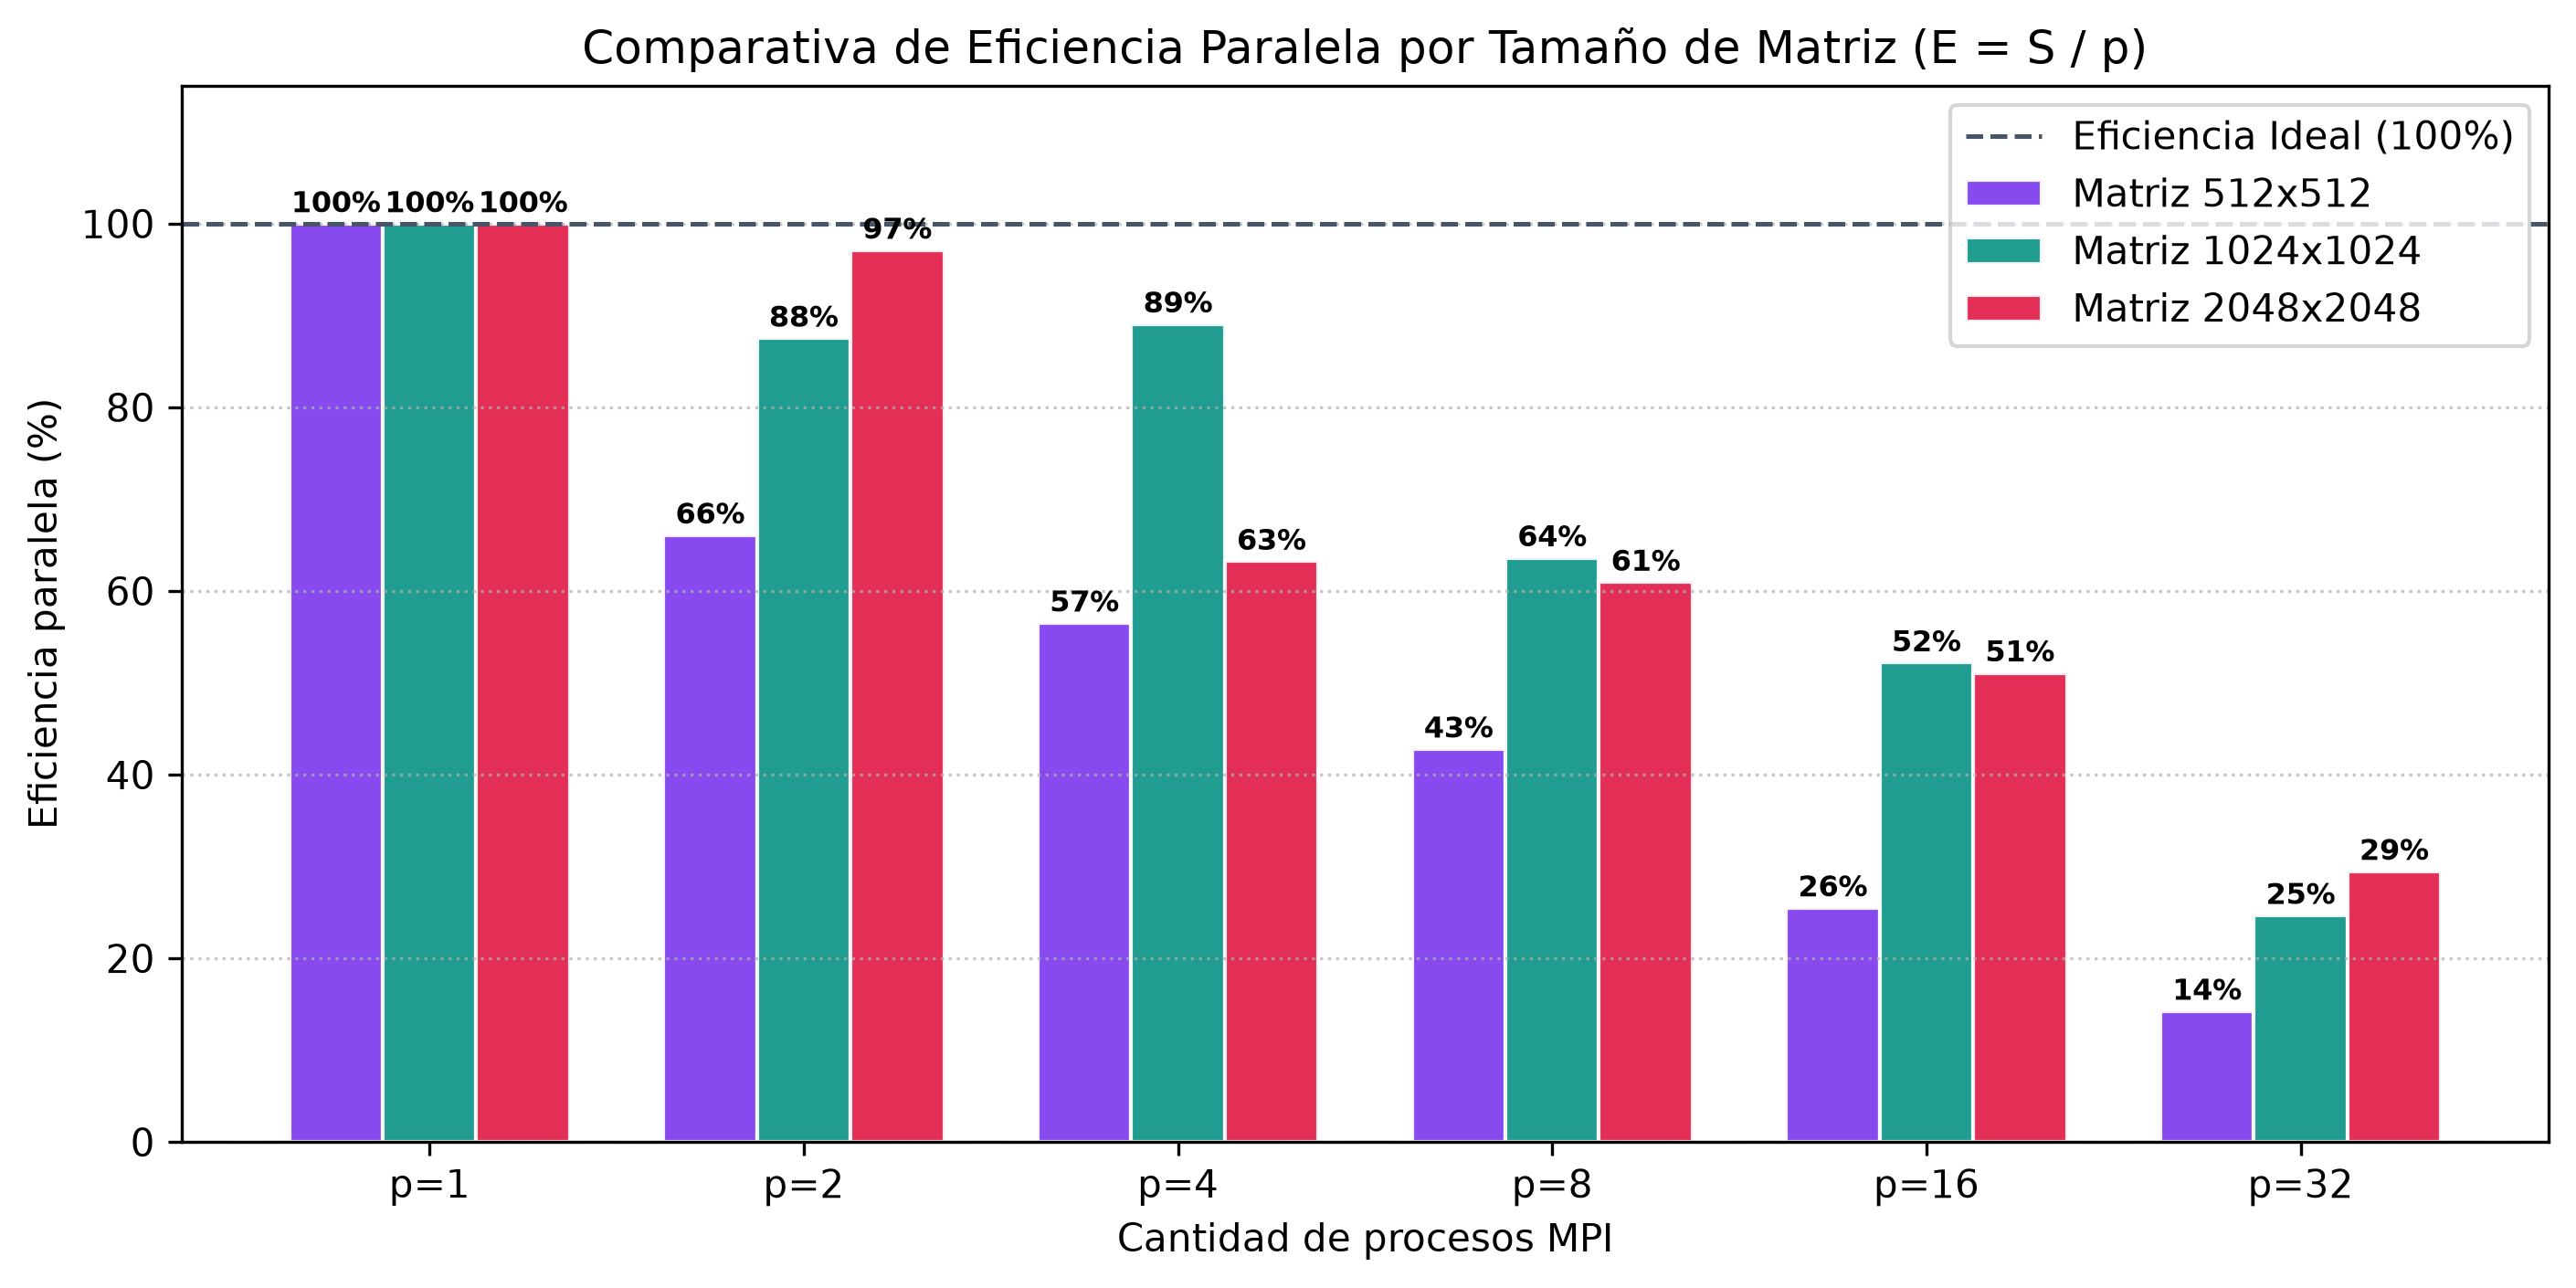

In [10]:
ancho = 0.25
desplazamientos = {512: -ancho, 1024: 0.0, 2048: ancho}

plt.figure(figsize=(9.5, 4.8), dpi=300)
plt.axhline(100.0, linestyle='--', color='#475569', linewidth=1.2, label='Eficiencia Ideal (100%)')

for N in dimensiones:
    barras = plt.bar(x_pos + desplazamientos[N], eficiencias_pct[N], width=ancho,
                     color=colores[N], edgecolor='white', alpha=0.92, label=f'Matriz {N}x{N}')
    for b in barras:
        h = b.get_height()
        plt.annotate(f'{h:.0f}%', (b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.8, fontweight='bold')

plt.xticks(x_pos, etiquetas_p)
plt.ylim(0, 115)
plt.xlabel('Cantidad de procesos MPI')
plt.ylabel('Eficiencia paralela (%)')
plt.title('Comparativa de Eficiencia Paralela por Tamaño de Matriz (E = S / p)')
plt.legend(loc='upper right')
plt.grid(True, axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e2_eficiencia_matrices.png', dpi=300)
plt.show()